# Homework 3

Repository: [https://github.com/courbel/DATA-37711](https://github.com/courbel/DATA-37711)

Homework 3 code: [https://github.com/courbel/DATA-37711/tree/main/homework_3](https://github.com/courbel/DATA-37711/tree/main/homework_3)

In [1]:
import time, warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, ParameterGrid
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import mean_squared_error, accuracy_score, log_loss

SEED = 0
_ = np.seterr(all="ignore")  # silence spurious BLAS matmul warnings on macOS

## Problem 1: Poisson boosting

### (a)

**i. Why Poisson?** $Y \in \{0, 1, 2, \dots\}$ is a count. The Poisson distribution is the standard model for counts: it puts mass only on the non-negative integers, has a single parameter (the rate $\mu = \mathbb{E}[Y \mid X]$), and arises naturally as the distribution of the number of events occurring independently at a constant rate. A Gaussian would put mass on negative and non-integer values.

**ii. Why $\exp(\cdot)$?** The Poisson rate must be positive, $\mu(X) > 0$, but a sum of regression trees $f(X) = \sum_j \lambda_j h_j(X)$ can be any real number. $\mu(X) = \exp(f(X))$ maps $\mathbb{R} \to (0, \infty)$, so every $f$ gives a valid model and boosting can take unconstrained additive steps. It is also the canonical link for the Poisson (the natural parameter is $\log \mu$), which makes the negative log-likelihood convex in $f$, and it makes the trees act multiplicatively on the rate: $\mu(X) = \prod_j e^{\lambda_j h_j(X)}$.

### (b) Loss

The loss is the negative log-likelihood. With $P(Y = y \mid X) = \mu^y e^{-\mu} / y!$ and $\mu = e^{f(x)}$:

$$L(f(x), Y) = -\log P(Y \mid X = x) = e^{f(x)} - Y f(x) + \log(Y!).$$

$\log(Y!)$ does not depend on $f$, so we can drop it and use $L(f(x), Y) = e^{f(x)} - Y f(x)$. Training minimizes the empirical risk $\frac{1}{n}\sum_{i=1}^n \big(e^{f(x_i)} - Y_i f(x_i)\big)$.

### (c) Gradient

$$\frac{dL}{df(x)} = e^{f(x)} - Y.$$

(The predicted rate minus the observed count. The second derivative $e^{f(x)} > 0$, so the loss is convex in $f$.)

### (d) Choosing each $h_j$ (first-order / gradient boosting)

1. Initialize with a constant: $f_0(x) = \log \bar{Y}$ (the minimizer of the empirical risk over constants).
2. At step $j$, given the current model $f_{j-1}$, compute the negative gradients (pseudo-residuals) at each training point:
$$r_i = -\frac{\partial L(f(x_i), Y_i)}{\partial f(x_i)}\Big|_{f = f_{j-1}} = Y_i - e^{f_{j-1}(x_i)}.$$
3. Choose $h_j$ as the regression tree that best approximates the negative gradient, i.e. fit a tree by least squares to $\{(x_i, r_i)\}_{i=1}^n$: $h_j = \arg\min_{h \in \text{trees}} \sum_i (r_i - h(x_i))^2$. This is the direction in function space (restricted to trees) closest to steepest descent.
4. Choose the step size by a line search on the actual loss, $\lambda_j = \arg\min_\lambda \sum_i L\big(f_{j-1}(x_i) + \lambda h_j(x_i), Y_i\big)$ (often multiplied by a shrinkage / learning rate $\nu \in (0, 1]$), and update $f_j = f_{j-1} + \lambda_j h_j$.
5. Repeat for a fixed number of steps (chosen e.g. on a validation set).

## Problem 2: Hyperparameter selection and generalization

### (a) Generalization bound

**Setup.** We fit $k$ models $\hat h_1, \dots, \hat h_k$ (one per hyperparameter setting) on a training set of size $n$. The test set $S = \{(x_i, y_i)\}_{i=1}^{l}$ is drawn i.i.d. from the data distribution, independently of the training set. Assume the loss is bounded, $\ell(h(x), y) \in [0, B]$ (e.g. $B = 1$ for 0-1 loss; for the wine data, quality is in $[0, 10]$, so squared error on predictions clipped to $[0, 10]$ is bounded by $B = 100$). Let $R(h) = \mathbb{E}[\ell(h(X), Y)]$ be the true risk and $\hat R_S(h) = \frac{1}{l}\sum_{i=1}^l \ell(h(x_i), y_i)$ the test risk. We select $\hat j = \arg\min_j \hat R_S(\hat h_j)$.

**Claim.** For any $\delta \in (0, 1)$, with probability at least $1 - \delta$ (over the draw of the test set),

$$\big|\hat R_S(\hat h_{\hat j}) - R(\hat h_{\hat j})\big| \;\le\; \max_{1 \le j \le k} \big|\hat R_S(\hat h_j) - R(\hat h_j)\big| \;\le\; B\sqrt{\frac{\log(2k/\delta)}{2l}}.$$

**Proof.** Condition on the training set; then $\hat h_1, \dots, \hat h_k$ are fixed functions, and because the test set is independent of the training set, the test losses $\ell(\hat h_j(x_i), y_i)$, $i = 1, \dots, l$, are i.i.d. in $[0, B]$ with mean $R(\hat h_j)$. Hoeffding's inequality gives, for each fixed $j$ and any $\varepsilon > 0$,
$$P\big(|\hat R_S(\hat h_j) - R(\hat h_j)| > \varepsilon\big) \le 2\exp\!\left(-\frac{2 l \varepsilon^2}{B^2}\right).$$
The selected index $\hat j$ depends on $S$, so we cannot apply Hoeffding to $\hat h_{\hat j}$ directly. Instead, take a union bound over the $k$ candidates:
$$P\Big(\max_j |\hat R_S(\hat h_j) - R(\hat h_j)| > \varepsilon\Big) \le \sum_{j=1}^k P\big(|\hat R_S(\hat h_j) - R(\hat h_j)| > \varepsilon\big) \le 2k\exp\!\left(-\frac{2 l \varepsilon^2}{B^2}\right).$$
Setting the right-hand side equal to $\delta$ gives $\varepsilon = B\sqrt{\log(2k/\delta)/(2l)}$. On the complementary event (probability $\ge 1 - \delta$), every candidate's test risk is within $\varepsilon$ of its true risk, in particular the selected one, whatever $\hat j$ is. Since this holds conditional on every training set, it also holds unconditionally. $\blacksquare$

**Consequence.** On the same event, the selected model is also nearly the best of the $k$: $R(\hat h_{\hat j}) \le \hat R_S(\hat h_{\hat j}) + \varepsilon \le \hat R_S(\hat h_{j^*}) + \varepsilon \le \min_j R(\hat h_j) + 2\varepsilon$.

The bound depends only on $l$ and $k$ (through $\sqrt{\log k / l}$), not on $n$: $n$ affects how good the candidate models are, not how well the test set estimates their risk. Compared with a single model (where the bound is $B\sqrt{\log(2/\delta)/(2l)}$), selecting among $k$ models costs an extra $\log k$ term.

### (b) Using the same test set for selection and for estimating error

The reported number $\hat R_S(\hat h_{\hat j}) = \min_j \hat R_S(\hat h_j)$ is a minimum of $k$ noisy estimates, so it is **optimistically biased**: $\mathbb{E}[\min_j \hat R_S(\hat h_j)] \le \min_j R(\hat h_j)$, and we pick whichever model happened to get lucky on these particular $l$ points. The bound in (a) only controls this bias at rate $\sqrt{\log k / l}$. When $k$ is large relative to $l$ (e.g. $k \gg e^{l}$, or simply many configurations relative to a small test set), the bound becomes vacuous and the bias can be large: in the extreme, with enough candidates, some model will fit the test labels almost perfectly by chance (we are effectively training on the test set), and the reported error will be far below the true error. The test set no longer gives an unbiased estimate of generalization error, and the selected hyperparameters may themselves be overfit to the test set rather than truly best.

### (c) Train / validation / test on the white wine data

Split: 70% train, 10% validation, 20% test. Model classes: `KNeighborsRegressor` (with standardized features, since KNN is distance-based) and `RandomForestRegressor`. Each grid has more parameter sets than there are validation points.

In [2]:
wine = pd.read_csv("data/winequality-white.csv", sep=";")
X = wine.drop(columns="quality").values
y = wine["quality"].values.astype(float)

X_tr, X_rest, y_tr, y_rest = train_test_split(X, y, train_size=0.7, random_state=SEED)
X_va, X_te, y_va, y_te = train_test_split(X_rest, y_rest, test_size=2/3, random_state=SEED)
print(f"train {len(y_tr)}, validation {len(y_va)}, test {len(y_te)}")
print(f"baseline (predict train mean): val MSE {mean_squared_error(y_va, np.full_like(y_va, y_tr.mean())):.3f}, "
      f"test MSE {mean_squared_error(y_te, np.full_like(y_te, y_tr.mean())):.3f}")

train 3428, validation 490, test 980
baseline (predict train mean): val MSE 0.809, test MSE 0.815


**Hyperparameters.**

- **KNN:** `n_neighbors` (number of neighbours averaged; small = low bias / high variance), `weights` (`uniform` average or `distance`-weighted average, which favours closer neighbours), `p` (exponent of the Minkowski distance: 1 = Manhattan, 2 = Euclidean, 3).
- **Random forest:** `n_estimators` (number of trees; more trees = lower variance), `max_depth` (maximum tree depth), `min_samples_leaf` (minimum samples per leaf; larger = smoother trees), `max_features` (fraction of features considered at each split; smaller = more decorrelated trees), `max_samples` (fraction of the training set bootstrapped for each tree).

In [3]:
knn_grid = ParameterGrid({
    "n_neighbors": list(range(1, 101)),
    "weights": ["uniform", "distance"],
    "p": [1, 2, 3],
})
rf_grid = ParameterGrid({
    "n_estimators": [50, 100],
    "max_depth": [None, 4, 8, 12, 16, 20],
    "min_samples_leaf": [1, 2, 4, 8, 16],
    "max_features": [0.2, 0.4, 0.6, 0.8, 1.0],
    "max_samples": [0.5, None],
})
print(f"validation points: {len(y_va)}; KNN parameter sets: {len(knn_grid)}; RF parameter sets: {len(rf_grid)}")

def make_knn(params):
    return make_pipeline(StandardScaler(), KNeighborsRegressor(**params))

def make_rf(params):
    return RandomForestRegressor(**params, random_state=SEED, n_jobs=-1)

def grid_search(make_model, grid):
    rows = []
    for params in grid:
        m = make_model(params).fit(X_tr, y_tr)
        rows.append({**params,
                     "val_mse": mean_squared_error(y_va, m.predict(X_va)),
                     "test_mse": mean_squared_error(y_te, m.predict(X_te))})
    return pd.DataFrame(rows)

t = time.time(); knn_res = grid_search(make_knn, knn_grid); print(f"KNN grid: {time.time() - t:.0f}s")
t = time.time(); rf_res = grid_search(make_rf, rf_grid);   print(f"RF grid: {time.time() - t:.0f}s")

validation points: 490; KNN parameter sets: 600; RF parameter sets: 600


KNN grid: 53s


RF grid: 52s


The test MSE of every configuration is recorded only to plot the validation/test relationship below; selection uses the validation score only.

In [4]:
summary = []
for name, res in [("KNeighborsRegressor", knn_res), ("RandomForestRegressor", rf_res)]:
    i = res["val_mse"].idxmin()
    best = res.loc[i]
    grid = knn_grid if name.startswith("K") else rf_grid
    params = list(grid)[i]
    summary.append({"model": name, "best params (by validation)": params,
                    "validation MSE": best["val_mse"], "test MSE": best["test_mse"],
                    "test - val": best["test_mse"] - best["val_mse"],
                    "corr(val, test) over grid": res["val_mse"].corr(res["test_mse"])})
pd.set_option("display.max_colwidth", None)
pd.DataFrame(summary).round(4)

,model,best params (by validation),validation MSE,test MSE,test - val,"corr(val, test) over grid"
0,KNeighborsRegressor,"{'n_neighbors': 16, 'p': 1, 'weights': 'distance'}",0.4000,0.4615,0.0614,0.9889
1,RandomForestRegressor,"{'max_depth': 20, 'max_features': 0.2, 'max_samples': None, 'min_samples_leaf': 1, 'n_estimators': 100}",0.3802,0.4468,0.0665,0.9941


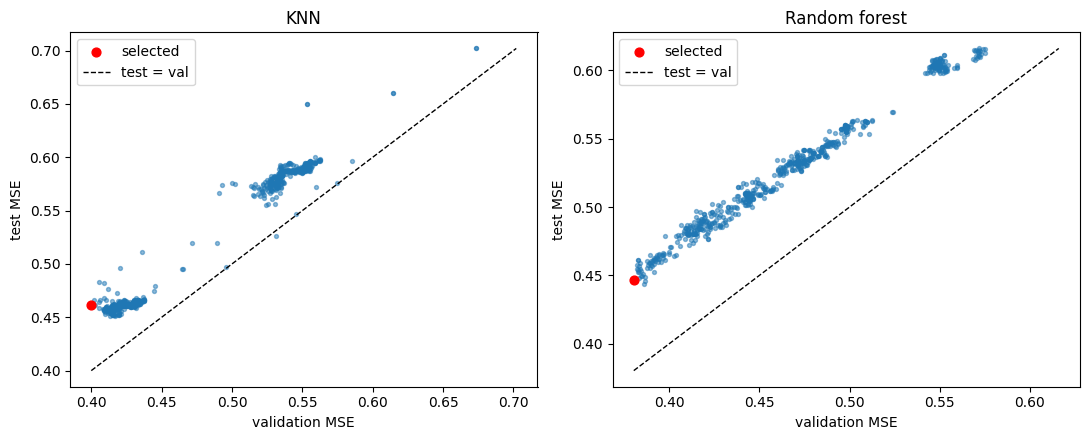

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (name, res) in zip(axes, [("KNN", knn_res), ("Random forest", rf_res)]):
    ax.scatter(res["val_mse"], res["test_mse"], s=8, alpha=0.5)
    b = res.loc[res["val_mse"].idxmin()]
    ax.scatter(b["val_mse"], b["test_mse"], color="red", s=40, label="selected")
    lo, hi = res[["val_mse", "test_mse"]].min().min(), res[["val_mse", "test_mse"]].max().max()
    ax.plot([lo, hi], [lo, hi], "k--", lw=1, label="test = val")
    ax.set_xlabel("validation MSE"); ax.set_ylabel("test MSE"); ax.set_title(name); ax.legend()
plt.tight_layout(); plt.show()

**Relationship between validation and test risk.** Across each grid, validation MSE and test MSE are strongly positively correlated (see the table and the scatter plots): configurations that do well on the validation set also tend to do well on the test set, so the validation set is useful for ranking hyperparameters. The random forest has clearly lower test MSE than KNN.

For the *selected* configuration, though, the validation MSE is an optimistic estimate of its true risk: it is the minimum over many noisy validation estimates (more configurations than validation points), so it is biased downward, exactly the effect described in (b). The test set was not used for selection, so the test MSE of the selected model is an unbiased estimate of its risk, and it is the number to report. Here the test MSE is higher than the validation MSE for both model classes. (Part of any gap is also just that the validation and test sets are different random samples; with only 490 validation points, the validation MSE itself is noisy.)

## Problem 3: Generalization of boosting as trees are added

I treat the first column (0/1) as a binary label and fit `GradientBoostingClassifier` (scikit-learn defaults: depth-3 trees, learning rate 0.1) with 1, 10, 100, 300 and 1000 trees. With only 500 points, a single train/test split is noisy, so I report 5-fold stratified cross-validation (train and held-out accuracy and log-loss, averaged over folds). I also show the full held-out curve as trees are added, using `staged_predict`.

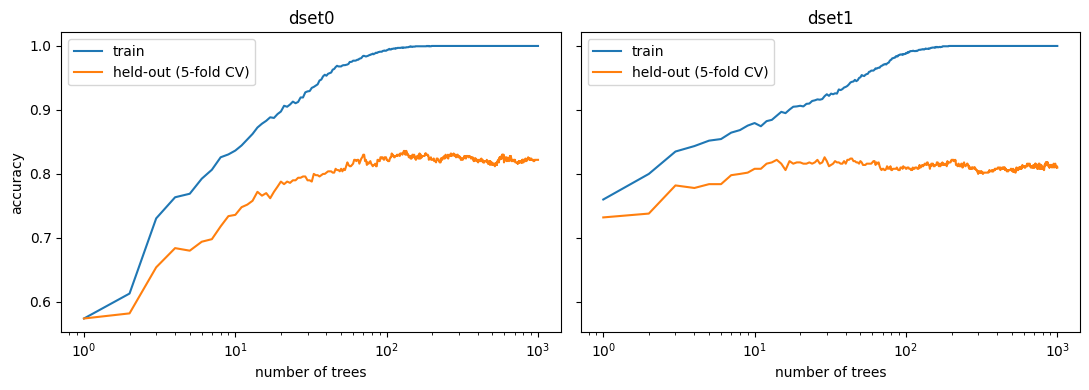

In [6]:
N_TREES = [1, 10, 100, 300, 1000]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

def boosting_study(path):
    d = pd.read_csv(path, header=None)
    Xd, yd = d.iloc[:, 1:].values, d.iloc[:, 0].astype(int).values
    curves_tr, curves_te, rows = [], [], []
    for tr, te in cv.split(Xd, yd):
        m = GradientBoostingClassifier(n_estimators=max(N_TREES), random_state=SEED).fit(Xd[tr], yd[tr])
        acc_tr = [accuracy_score(yd[tr], p) for p in m.staged_predict(Xd[tr])]
        acc_te = [accuracy_score(yd[te], p) for p in m.staged_predict(Xd[te])]
        ll_te = [log_loss(yd[te], p) for p in m.staged_predict_proba(Xd[te])]
        curves_tr.append(acc_tr); curves_te.append(acc_te)
        for n in N_TREES:
            rows.append({"trees": n, "train acc": acc_tr[n - 1], "held-out acc": acc_te[n - 1], "held-out log-loss": ll_te[n - 1]})
    table = pd.DataFrame(rows).groupby("trees").mean().round(3)
    lr_acc = np.mean([accuracy_score(yd[te], make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)).fit(Xd[tr], yd[tr]).predict(Xd[te]))
                      for tr, te in cv.split(Xd, yd)])
    return table, np.mean(curves_tr, 0), np.mean(curves_te, 0), lr_acc

results = {name: boosting_study(f"data/{name}.csv") for name in ["dset0", "dset1"]}

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, (name, (_, ctr, cte, _)) in zip(axes, results.items()):
    ax.plot(np.arange(1, len(ctr) + 1), ctr, label="train")
    ax.plot(np.arange(1, len(cte) + 1), cte, label="held-out (5-fold CV)")
    ax.set_xscale("log"); ax.set_xlabel("number of trees"); ax.set_title(name); ax.legend()
axes[0].set_ylabel("accuracy"); plt.tight_layout(); plt.show()

### (a) dset0

In [7]:
table0, _, _, lr0 = results["dset0"]
print(f"logistic regression held-out accuracy: {lr0:.3f}")
table0

logistic regression held-out accuracy: 0.646


,train acc,held-out acc,held-out log-loss
trees,,,
1,0.574,0.574,0.663
10,0.836,0.736,0.567
100,0.993,0.822,0.393
300,1.000,0.826,0.417
1000,1.000,0.822,0.731


**dset0.** With 1 tree the model is barely better than predicting the majority class. Held-out accuracy keeps improving substantially up to about 100 trees, and then stays roughly flat out to 1000 trees, even though training accuracy reaches 100% by about 300 trees. So adding trees beyond the point of zero training error does not noticeably hurt held-out accuracy: boosting is fairly resistant to overfitting in terms of classification error here. Held-out log-loss, however, is minimized around 100 trees and then increases sharply, because the later trees keep pushing the predicted probabilities toward 0 and 1 (overconfidence), which log-loss punishes on the misclassified points. A linear model (logistic regression) does poorly on this dataset, so the decision boundary is strongly nonlinear and needs many trees to represent.

### (b) dset1

In [8]:
table1, _, _, lr1 = results["dset1"]
print(f"logistic regression held-out accuracy: {lr1:.3f}")
table1

logistic regression held-out accuracy: 0.830


,train acc,held-out acc,held-out log-loss
trees,,,
1,0.760,0.732,0.645
10,0.880,0.808,0.467
100,0.989,0.808,0.400
300,1.000,0.800,0.501
1000,1.000,0.810,0.952


**dset1.** Here a single tree already gets well above chance, and held-out accuracy essentially reaches its plateau by about 10 trees. Adding more trees after that brings no improvement: training accuracy climbs to 100% while held-out accuracy stays flat, so the extra trees only fit noise in the training set (the train/test gap widens). As with dset0, held-out log-loss is best around 100 trees and gets much worse at 300 and 1000 trees. Logistic regression does as well as boosting on this dataset.

### (c) Why the behaviour differs

The two datasets differ in the complexity of the true decision boundary $P(Y = 1 \mid X)$. In **dset1** the signal is simple, close to linear (logistic regression matches boosting; the label is mostly driven by the first covariate), so a handful of depth-3 trees captures it and every later tree mostly fits label noise: held-out performance saturates early and the model starts overfitting (the train/test gap widens with no gain). In **dset0** the boundary is nonlinear (logistic regression is only about 65% accurate), so boosting needs many more trees to approximate it, and held-out accuracy keeps improving up to ~100 trees before levelling off. In both cases the labels are noisy (the best achievable accuracy is only about 82–83%, so the Bayes error is well above zero): once the signal is learned, more trees cannot reduce the test error further, training error is driven to zero by memorizing noisy points, and the predicted probabilities become overconfident, so log-loss gets worse even though held-out accuracy degrades only slowly.